In [1]:
!pip install -q datasets torchsummary
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [2]:
from datasets import load_dataset
raw = load_dataset("timm/resisc45")

all_names = raw['train'].features['label'].names
selected = ['forest', 'river', 'lake', 'beach', 'desert',
            'airport', 'industrial area', 'harbor', 'mountain', 'rectangular farmland']

class_ids = [i for i, n in enumerate(all_names) if n.replace('_', ' ') in selected]
classes = [all_names[i].replace('_', ' ') for i in class_ids]
id_map = {old: new for new, old in enumerate(class_ids)}

# keep only the selected classes
train_raw = raw['train'].filter(lambda l: l in class_ids, input_columns='label')
val_raw = raw['validation'].filter(lambda l: l in class_ids, input_columns='label')
test_raw = raw['test'].filter(lambda l: l in class_ids, input_columns='label')

README.md:   0%|          | 0.00/3.11k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  255MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 85.1MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 85.2MB            

... (3 outputs left out)

Generating test split:   0%|          | 0/6300 [00:00<?, ? examples/s]

Filter:   0%|          | 0/18900 [00:00<?, ? examples/s]

Filter:   0%|          | 0/6300 [00:00<?, ? examples/s]

Filter:   0%|          | 0/6300 [00:00<?, ? examples/s]

In [3]:
print('Dataset Summary')
print('Train Data: ', len(train_raw))
print('Validation Data: ', len(val_raw))
print('Test Data: ', len(test_raw))
print('Classess and Indices: ', {c: i for i, c in enumerate(classes)})

Dataset Summary
Train Data:  4214
Validation Data:  1386
Test Data:  1400
Classess and Indices:  {'airport': 0, 'beach': 1, 'desert': 2, 'forest': 3, 'harbor': 4, 'industrial area': 5, 'lake': 6, 'mountain': 7, 'rectangular farmland': 8, 'river': 9}


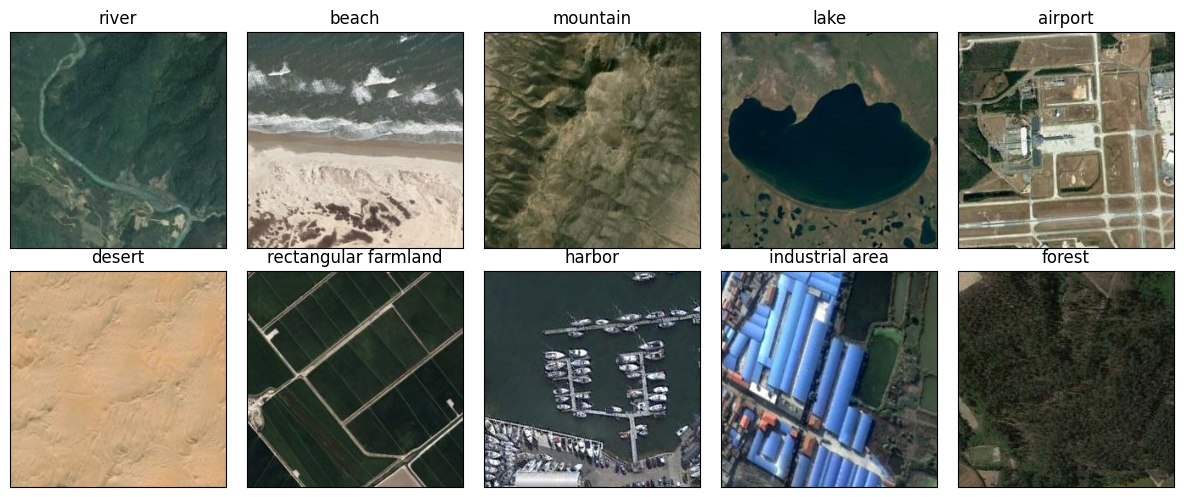

In [4]:
ROWS, COLS = 2, 5
fig, axes = plt.subplots(ROWS, COLS, figsize=(12, 5))
shown = set()
ix = 0
while len(shown) < len(classes):
    item = train_raw[ix]
    c = id_map[item['label']]
    if c not in shown:
        ax = axes.flat[len(shown)]
        ax.imshow(item['image'])
        ax.set_title(classes[c])
        ax.set(xticks=[], yticks=[])
        shown.add(c)
    ix += 1
plt.tight_layout()
plt.show()

In [5]:
size = 64
train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

class RESISCDataset(Dataset):
    def __init__(self, hf_data, transform):
        self.hf_data = hf_data
        self.transform = transform

    def __getitem__(self, ix):
        item = self.hf_data[ix]
        img = self.transform(item['image'].convert('RGB'))
        return img, id_map[item['label']]

    def __len__(self):
        return len(self.hf_data)

train_data = RESISCDataset(train_raw, train_transform)
val_data = RESISCDataset(val_raw, val_transform)
test_data = RESISCDataset(test_raw, val_transform)

In [6]:
## HyperParameters ##
batch_size = 32
learning_rate = 1e-3
epoch_number = 20

In [7]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

In [8]:
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #Classifier
        nn.Flatten(),
        nn.Linear(128*8*8, 256),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(256, len(classes))
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [9]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [10]:
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3, 64, 64));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
       BatchNorm2d-2           [-1, 32, 64, 64]              64
              ReLU-3           [-1, 32, 64, 64]               0
         MaxPool2d-4           [-1, 32, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]          18,496
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
         MaxPool2d-8           [-1, 64, 16, 16]               0
            Conv2d-9          [-1, 128, 16, 16]          73,856
      BatchNorm2d-10          [-1, 128, 16, 16]             256
             ReLU-11          [-1, 128, 16, 16]               0
        MaxPool2d-12            [-1, 128, 8, 8]               0
          Flatten-13                 [-1, 8192]               0
           Linear-14                  [

In [11]:
## Training Loop ###
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc = validation(val_dl, model, loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/20] | Train Loss: 1.8641 | Train Accuracy: 40.41% | Val Loss: 1.1880 | Val Accuracy: 57.43%
Epoch [2/20] | Train Loss: 1.4332 | Train Accuracy: 50.85% | Val Loss: 1.2252 | Val Accuracy: 57.79%
Epoch [3/20] | Train Loss: 1.3036 | Train Accuracy: 54.25% | Val Loss: 0.9597 | Val Accuracy: 67.46%
Epoch [4/20] | Train Loss: 1.2591 | Train Accuracy: 56.15% | Val Loss: 0.9075 | Val Accuracy: 68.40%
Epoch [5/20] | Train Loss: 1.2230 | Train Accuracy: 58.35% | Val Loss: 0.9479 | Val Accuracy: 68.61%
Epoch [6/20] | Train Loss: 1.1582 | Train Accuracy: 58.42% | Val Loss: 1.0148 | Val Accuracy: 64.07%
Epoch [7/20] | Train Loss: 1.1416 | Train Accuracy: 61.13% | Val Loss: 0.8281 | Val Accuracy: 71.50%
Epoch [8/20] | Train Loss: 1.1122 | Train Accuracy: 62.27% | Val Loss: 0.8667 | Val Accuracy: 70.42%
Epoch [9/20] | Train Loss: 1.0605 | Train Accuracy: 63.53% | Val Loss: 0.7840 | Val Accuracy: 72.66%
Epoch [10/20] | Train Loss: 1.0460 | Train Accuracy: 64.19% | Val Loss: 0.9111 | Val Accura

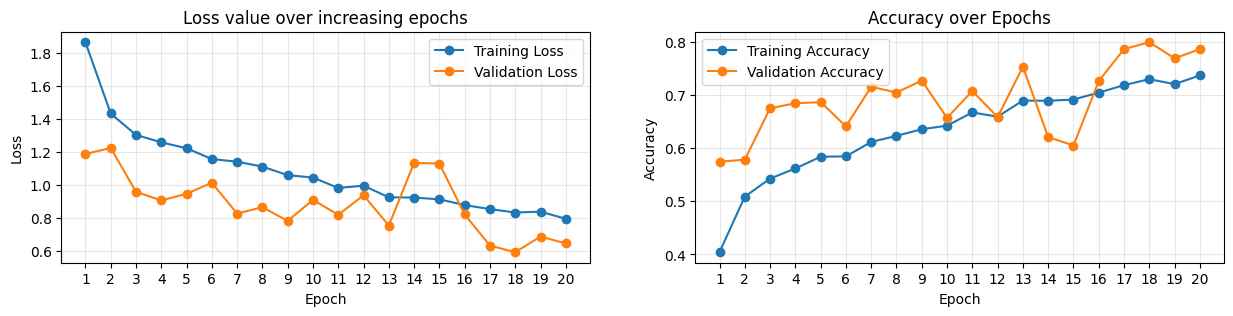

In [12]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

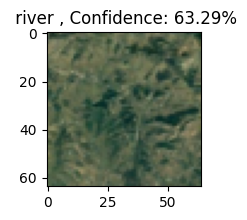

In [13]:
model.eval()
test_img, label = test_data[2]
img = test_img.view(-1, 3, size, size).to(device)

output = model(img)
pred = torch.exp(output)/torch.sum(torch.exp(output))
confidence, index = pred.max(-1)

plt.figure(figsize=(2,2))
plt.imshow(test_img.view(3, size, size).permute(1, 2, 0))
plt.title(f' {classes[index]} , Confidence: {confidence.item()*100:0.2f}%')
plt.show()

In [14]:
test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.64 , Test Accuracy: 76.43%


                      precision    recall  f1-score   support

             airport     0.7000    0.4753    0.5662       162
               beach     0.6028    0.9923    0.7500       130
              desert     0.8881    0.8699    0.8789       146
              forest     0.9211    0.9589    0.9396       146
              harbor     0.9606    0.8592    0.9071       142
     industrial area     0.8837    0.8143    0.8476       140
                lake     0.9515    0.7481    0.8376       131
            mountain     0.8095    0.4435    0.5730       115
rectangular farmland     0.6359    0.8667    0.7335       135
               river     0.5429    0.6209    0.5793       153

            accuracy                         0.7643      1400
           macro avg     0.7896    0.7649    0.7613      1400
        weighted avg     0.7876    0.7643    0.7610      1400



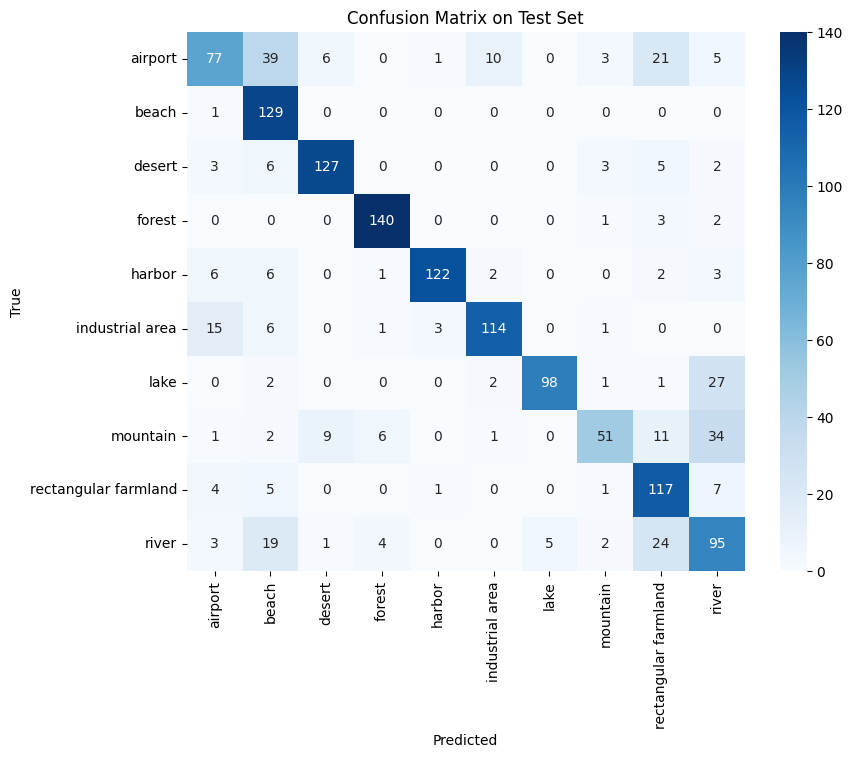

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

@torch.no_grad()
def get_predictions(data_loader, model):
    model.eval()
    preds, labels = [], []
    for x, y in data_loader:
        prediction = model(x.to(device))
        preds.extend(prediction.argmax(-1).cpu().numpy())
        labels.extend(y.numpy())
    return labels, preds

labels, preds = get_predictions(test_dl, model)
print(classification_report(labels, preds, target_names=classes, digits=4))

plt.figure(figsize=(9, 7))
sns.heatmap(confusion_matrix(labels, preds), annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix on Test Set")
plt.show()

In [16]:
torch.save(model.state_dict(), 'CNN_23-53645-3.pth')

In [17]:
import os
print(f"Model size: {os.path.getsize('CNN_23-53645-3.pth')/(1024*1024):.2f} MB")

saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('CNN_23-53645-3.pth'))
saved_model.eval()
summary(saved_model, (3, 64, 64))

test_loss, test_acc = validation(test_dl, saved_model, loss_fn)
print(f'Loaded Model Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Model size: 8.38 MB
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
       BatchNorm2d-2           [-1, 32, 64, 64]              64
              ReLU-3           [-1, 32, 64, 64]               0
         MaxPool2d-4           [-1, 32, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]          18,496
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
         MaxPool2d-8           [-1, 64, 16, 16]               0
            Conv2d-9          [-1, 128, 16, 16]          73,856
      BatchNorm2d-10          [-1, 128, 16, 16]             256
             ReLU-11          [-1, 128, 16, 16]               0
        MaxPool2d-12            [-1, 128, 8, 8]               0
          Flatten-13                 [-1, 8192]               0
           Linear-1